In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt 

DATA_DIR = r"C:\Users\HP\project_DL\archive (1)"
IMG_SIZE = (160, 160)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

all_ = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + "/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

n = tf.data.experimental.cardinality(all_).numpy()
test_batches = int(0.15 * n)
val_batches  = int(0.15 * n)

test_ds = all_.take(test_batches)
rest    = all_.skip(test_batches)
val_ds  = rest.take(val_batches)
train_ds = rest.skip(val_batches)

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())



Found 39209 files belonging to 43 classes.
Train batches: 431
Val batches: 91
Test batches: 91


In [5]:
base = tf.keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(160,160,3)
)
base.trainable = False

inputs = tf.keras.Input(shape=(160,160,3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(43, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 43)                  │          55,083 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,313,067 (8.82 MB)

 Trainable params: 55,083 (215.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
model.load_weights("best_gtsrb.keras")
print("Loaded best model weights successfully")

Loaded best model weights successfully


C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [7]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_gtsrb.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=[checkpoint, early],
    verbose=1
)


Epoch 1/2
431/431 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.9316 - loss: 0.2281
Epoch 1: val_accuracy improved from None to 0.94540, saving model to best_gtsrb.keras

Epoch 1: finished saving model to best_gtsrb.keras
431/431 ━━━━━━━━━━━━━━━━━━━━ 185s 391ms/step - accuracy: 0.9319 - loss: 0.2276 - val_accuracy: 0.9454 - val_loss: 0.2016
Epoch 2/2
431/431 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.9306 - loss: 0.2318
Epoch 2: val_accuracy did not improve from 0.94540
431/431 ━━━━━━━━━━━━━━━━━━━━ 165s 366ms/step - accuracy: 0.9314 - loss: 0.2298 - val_accuracy: 0.9439 - val_loss: 0.2035


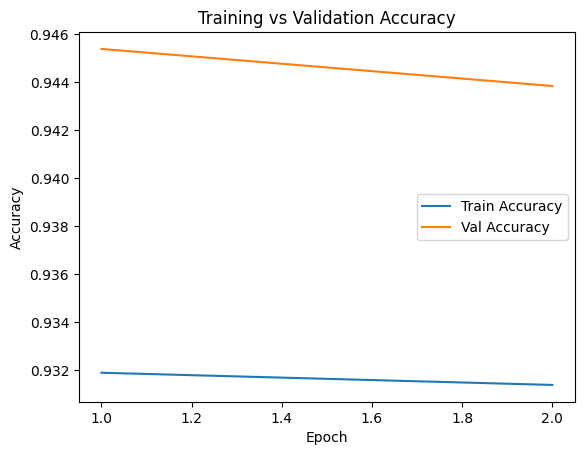

In [8]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs = range(1, len(acc) + 1)

plt.figure()
plt.plot(epochs, acc, label="Train Accuracy")
plt.plot(epochs, val_acc, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()


In [9]:
test_loss, test_acc = model.evaluate(test_ds)
print("Final Test Accuracy:", test_acc)


91/91 ━━━━━━━━━━━━━━━━━━━━ 28s 305ms/step - accuracy: 0.9439 - loss: 0.2130
Final Test Accuracy: 0.9438530206680298


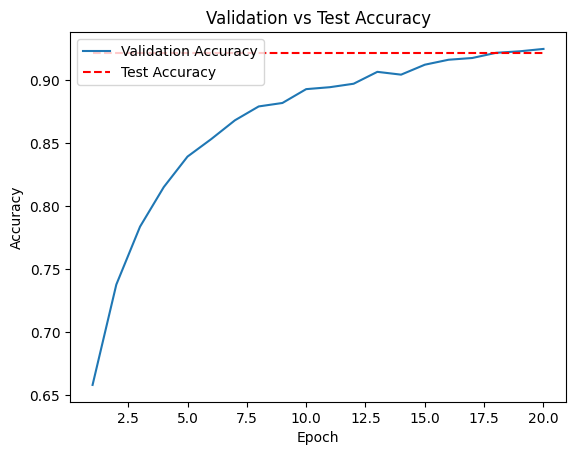

In [12]:
plt.figure()

plt.plot(epochs, val_acc, label="Validation Accuracy")

plt.hlines(
    y=test_acc,
    xmin=1,
    xmax=len(epochs),
    colors="r",
    linestyles="dashed",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation vs Test Accuracy")
plt.legend()
plt.show()


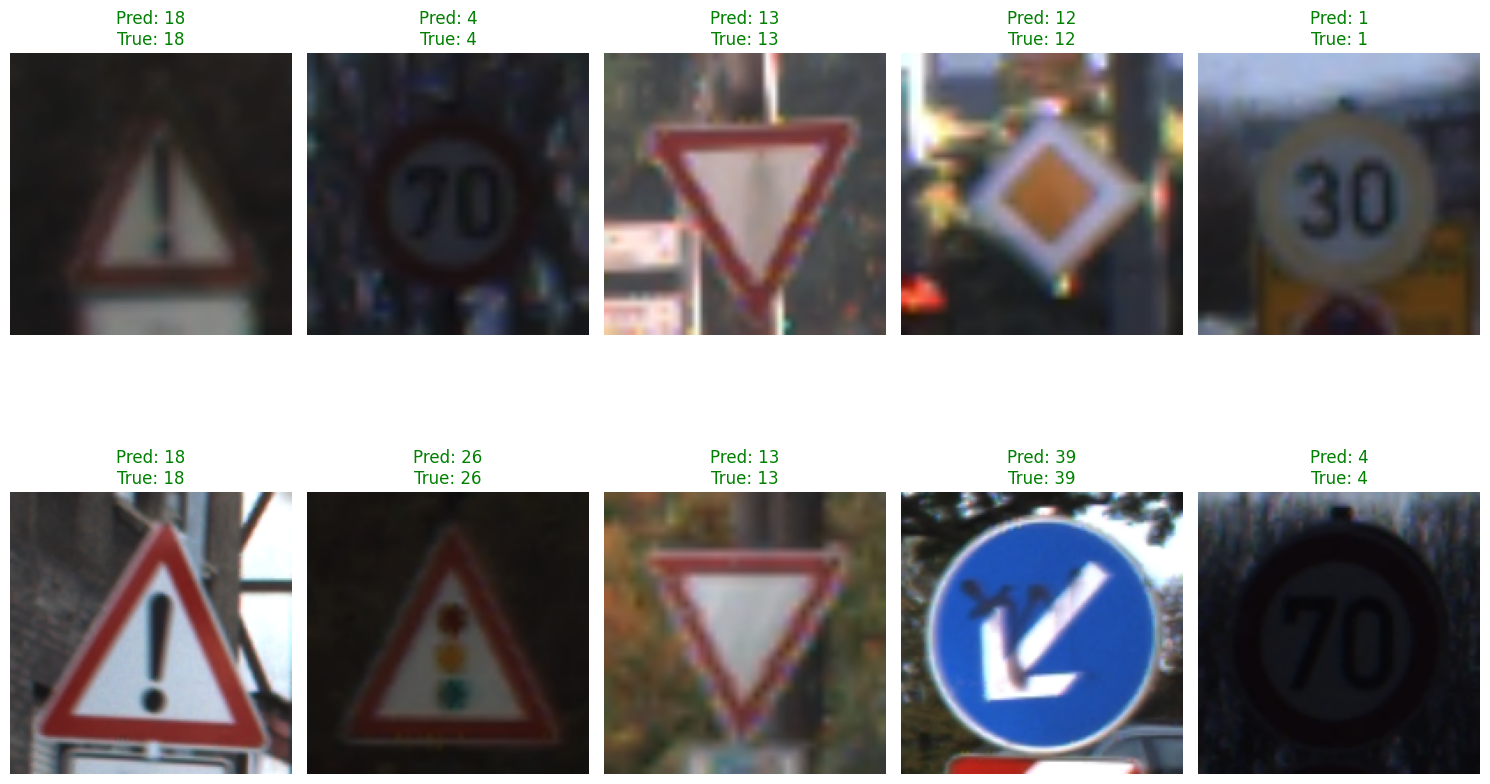

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = all_.class_names 

best_model = tf.keras.models.load_model("best_gtsrb.keras")


plt.figure(figsize=(15, 10))
shown = 0

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    preds = np.argmax(preds, axis=1)

    for i in range(len(images)):
        if shown == 10:
            break

        true_label = class_names[int(labels[i])]
        pred_label = class_names[int(preds[i])]
        color = "green" if true_label == pred_label else "red"

        plt.subplot(2, 5, shown + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
        plt.axis("off")

        shown += 1

    if shown == 10:
        break

plt.tight_layout()
plt.show()
